In [1]:
#Câu a
print("Phạm Đức Anh - 6451071001")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Đọc file Excel (header=None vì file gốc chưa có tên cột)
df = pd.read_excel('tb_tracking.xlsx', header=None)

# Gán tiêu đề cho 6 cột theo thứ tự yêu cầu
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']

print("--- Thông tin dữ liệu ban đầu ---")
df.info()
df.head(10)

Phạm Đức Anh - 6451071001
--- Thông tin dữ liệu ban đầu ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33340 entries, 0 to 33339
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           33339 non-null  float64       
 1   device_id    33339 non-null  float64       
 2   co_level     33339 non-null  float64       
 3   humidity     33339 non-null  float64       
 4   temperature  33339 non-null  float64       
 5   time         33339 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(5)
memory usage: 1.5 MB


,id,device_id,co_level,humidity,temperature,time
0,1.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:29
1,2.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:31
2,3.0,100.0,2.0,3.0,4.0,2016-12-20 12:52:35
3,4.0,100.0,2.0,3.0,400.0,2016-12-20 12:52:37
4,5.0,1.0,2.0,3.0,4.0,2016-12-20 13:02:01
5,6.0,100.0,2.0,3.0,400.0,2016-12-20 13:02:24
6,7.0,-1.0,0.0,83.0,28.0,2016-12-21 12:03:39
7,8.0,-1.0,0.0,83.0,28.0,2016-12-21 12:05:02
8,9.0,-1.0,0.0,83.0,28.0,2016-12-21 12:05:49
9,10.0,1.0,2.0,3.0,4.0,2016-12-21 12:08:58


In [2]:
#Câu b
print("Phạm Đức Anh - 6451071001")

# 1. Loại bỏ các dòng bị thiếu dữ liệu (NaN)
df = df.dropna()

# 2. Chuyển cột 'time' sang kiểu thời gian (datetime) để so sánh chính xác
df['time'] = pd.to_datetime(df['time'])

# 3. Loại bỏ dữ liệu từ ngày 03/01/2018 trở về trước (chỉ giữ lại dữ liệu từ 04/01/2018 trở đi)
df = df[df['time'].dt.date > pd.to_datetime('2018-01-03').date()].copy()

print("Số dòng dữ liệu hợp lệ còn lại:", len(df))
print("Thời gian sớm nhất sau khi lọc:", df['time'].min())
df.head(10)

Phạm Đức Anh - 6451071001
Số dòng dữ liệu hợp lệ còn lại: 1819
Thời gian sớm nhất sau khi lọc: 2018-01-04 00:01:30


,id,device_id,co_level,humidity,temperature,time
31518,31519.0,99005.0,28.0,74.0,2600610.0,2018-01-04 00:01:30
31519,31520.0,99005.0,28.0,74.0,2595870.0,2018-01-04 00:06:26
31520,31521.0,99005.0,28.0,74.0,2596150.0,2018-01-04 00:11:22
31521,31522.0,99005.0,28.0,75.0,2592510.0,2018-01-04 00:16:18
31522,31523.0,99005.0,28.0,75.0,2589980.0,2018-01-04 00:21:13
31523,31524.0,99005.0,28.0,75.0,2584680.0,2018-01-04 00:26:09
31524,31525.0,99005.0,28.0,75.0,2583160.0,2018-01-04 00:31:05
31525,31526.0,99005.0,28.0,75.0,2581560.0,2018-01-04 00:36:01
31526,31527.0,99005.0,28.0,75.0,2579070.0,2018-01-04 00:40:57
31527,31528.0,99005.0,28.0,75.0,2575580.0,2018-01-04 00:45:53


In [3]:
#Câu c
print("Phạm Đức Anh - 6451071001")

# Bóc tách giờ và phút từ cột 'time' để quy đổi ra tổng số phút trong ngày
df['minutes'] = df['time'].dt.hour * 60 + df['time'].dt.minute

# Kiểm tra kết quả bóc tách
print(df[['id', 'time', 'minutes']].head(10))

Phạm Đức Anh - 6451071001
            id                time  minutes
31518  31519.0 2018-01-04 00:01:30        1
31519  31520.0 2018-01-04 00:06:26        6
31520  31521.0 2018-01-04 00:11:22       11
31521  31522.0 2018-01-04 00:16:18       16
31522  31523.0 2018-01-04 00:21:13       21
31523  31524.0 2018-01-04 00:26:09       26
31524  31525.0 2018-01-04 00:31:05       31
31525  31526.0 2018-01-04 00:36:01       36
31526  31527.0 2018-01-04 00:40:57       40
31527  31528.0 2018-01-04 00:45:53       45


Phạm Đức Anh - 6451071001


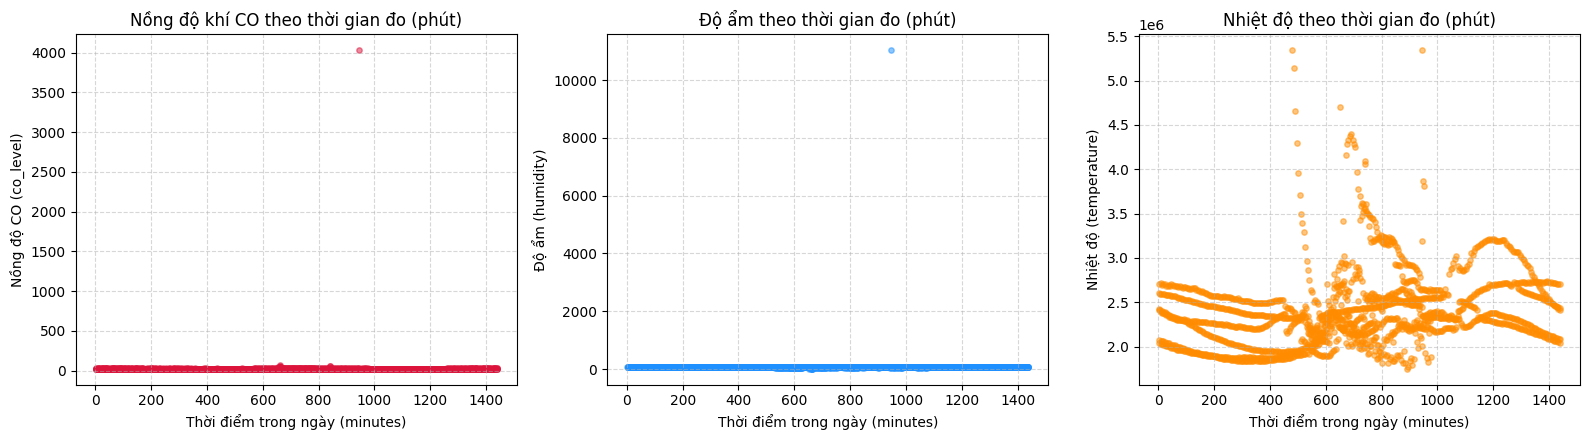

In [4]:
#Câu d
print("Phạm Đức Anh - 6451071001")

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4.5))

# 1. Biểu đồ phân tán Nồng độ khí CO (co_level) theo minutes
axes[0].scatter(df['minutes'], df['co_level'], color='crimson', alpha=0.5, s=15)
axes[0].set_title('Nồng độ khí CO theo thời gian đo (phút)')
axes[0].set_xlabel('Thời điểm trong ngày (minutes)')
axes[0].set_ylabel('Nồng độ CO (co_level)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Biểu đồ phân tán Độ ẩm (humidity) theo minutes
axes[1].scatter(df['minutes'], df['humidity'], color='dodgerblue', alpha=0.5, s=15)
axes[1].set_title('Độ ẩm theo thời gian đo (phút)')
axes[1].set_xlabel('Thời điểm trong ngày (minutes)')
axes[1].set_ylabel('Độ ẩm (humidity)')
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. Biểu đồ phân tán Nhiệt độ (temperature) theo minutes
axes[2].scatter(df['minutes'], df['temperature'], color='darkorange', alpha=0.5, s=15)
axes[2].set_title('Nhiệt độ theo thời gian đo (phút)')
axes[2].set_xlabel('Thời điểm trong ngày (minutes)')
axes[2].set_ylabel('Nhiệt độ (temperature)')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()